In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import importlib
import stmpy
import stmpy.tools as st
import stmpy.driftcorr as dfc
import h5py

import os
import importlib

from spgl1 import spgl1, spg_lasso, spg_bp, spg_bpdn, spg_mmv
from scipy.sparse.linalg import LinearOperator

In [2]:
def find_pts(x1, x2):
    x = lambda y: (y-x1[1])/((x2[1]-x1[1])/(x2[0]-x1[0])) + x1[0]
    return x

def get_snr(fts, n, pt0, pt1, range_signal, range_noise, ):
    cuts = []
    snr = []
    for i in range(n):
        r1, cut1 = stmpy.tools.linecut(fts[i], p0=pt0, p1=pt1, width=1, show=True, ax=gca())
        cuts.append(cut1)
        signal = mean(cut1[range_signal])
        noise = mean(cut1[range_noise])
        snr.append(signal / noise)
    return cuts, snr

# Load data

In [3]:
d1_true = stmpy.load("../data/Grid Spectroscopy-BSCCO-2022-09-04-002.3ds", biasOffset=False)

File import successful.


In [4]:
d = stmpy.load('../data/2022-09-05-BSCCO-SparseSamplingDOS-001.3ds', biasOffset=False)

File import successful.


In [5]:
t = stmpy.load('../data/2022-09-05_BSCCO_SparseSamplingTopo001.sxm')

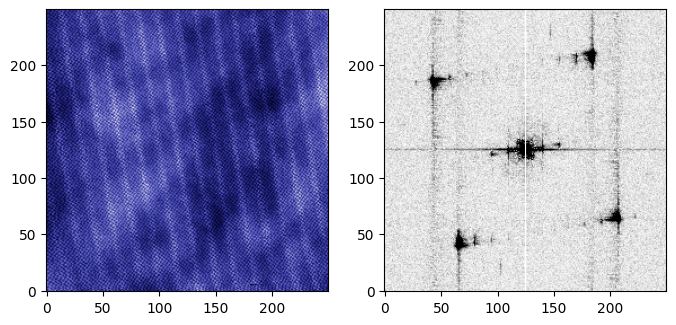

In [6]:
t.z = st.lineSubtract(st.nsigma_local(t.Z), 2)

dfc.display(t.z)


In [7]:
ri_temp = np.loadtxt("../data/mask_250x250.txt")

ri = np.array([int(k)-1 for k in ri_temp])

In [8]:
nx = 250
ny = 250

class partialFourier(LinearOperator):
    def __init__(self, idx, n):
        self.idx = idx
        self.n = n
        self.shape = (len(idx), n)
        self.dtype = np.complex128
    def _matvec(self, x):
        # % y = P(idx) * FFT(x)
        z = np.fft.fft(x) / np.sqrt(self.n)
        return z[self.idx]
    def _rmatvec(self, x):
        z = np.zeros(self.n,dtype=complex)
        z[self.idx] = x
        return np.fft.ifft(z) * np.sqrt(self.n)
n = nx * ny

# % Create partial Fourier operator with rows idx
idx=ri
opA = partialFourier(idx=ri, n=n)


In [9]:
def reconstruct_from_indices(gt_flat, idx):
    """Noiseless CS reconstruction from spatial samples at idx."""
    k = len(idx)
    b_sim = gt_flat[idx]
    b_zeroDC = b_sim - np.mean(b_sim)
    op = partialFourier(idx=idx, n=len(gt_flat))
    sigma = 1e-2 * np.linalg.norm(b_zeroDC) / np.sqrt(k)
    x, resid, grad, info = spg_bpdn(op, b_zeroDC, sigma, iter_lim=1e5, verbosity=0)
    rec_zeroDC = np.real(np.fft.ifft(x).reshape(nx, ny))
    return rec_zeroDC + np.mean(b_sim)  # restore DC

def ft_linecut_snr(ft_2d, angle_deg=51.5, noise_range=slice(None, 30), signal_range=slice(60, 90), width=3):
    """SNR from FT linecut: mean(signal region) / mean(noise region)."""
    H, W = ft_2d.shape
    L = W // 2 * 1.2
    center = (np.array([W, H]) - 1) / 2
    angle = angle_deg / 180 * np.pi
    p0 = center + np.array([L * np.cos(angle), L * np.sin(angle) * H / W])
    p1 = center - np.array([L * np.cos(angle), L * np.sin(angle) * H / W])
    fig, ax = plt.subplots()
    _, cut = stmpy.tools.linecut(ft_2d, p0=p0, p1=p1, width=width, show=True, ax=ax)
    plt.close(fig)
    return np.mean(cut[signal_range]) / np.mean(cut[noise_range])

# Reconstruct the 40 nm dos map

## Display the measured map

15625
(250, 250)


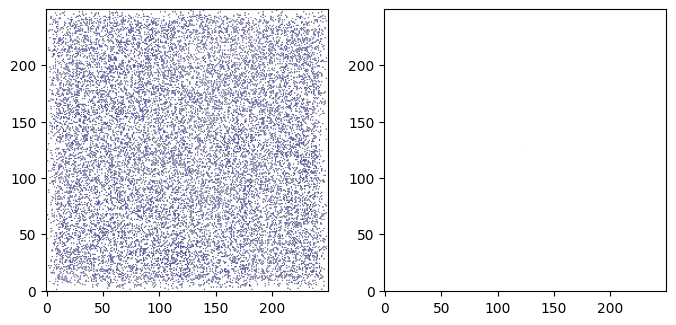

In [10]:
b = np.copy(d.LIY[-1,0,:]) * 1e15
print(len(b))
to_show = np.ones([nx, ny]) * np.mean(b)
result = np.full(nx * ny, np.nan)
result[ri] = b
to_show = result.reshape((nx, ny))
print(np.shape(to_show))
for i in range(len(ri)):
    index = ri[i]
    j = index // nx
    k = index % ny
    to_show[j, k] = b[i]
dfc.display(to_show)

In [11]:
# For figures, define clims based on GT data, and use those for both real-space and FT rows.
gt_fA = d1_true.LIY[-1] * 1e15
c_gt = np.nanmean(gt_fA)
s_gt = np.nanstd(gt_fA)
real_space_clims = [c_gt - 5*s_gt, c_gt + 5*s_gt]

gt_ft = st.fft(gt_fA, zeroDC=True)
c_ft = np.mean(gt_ft)
s_ft = np.std(gt_ft)
ft_clims = [0, c_ft + 5*s_ft]

In [12]:
# Compute ground truth SNR once as a reference
# gt_ft = st.fft(gt_fA, zeroDC=True) is already defined above
gt_snr_feat = ft_linecut_snr(gt_ft, angle_deg=51.5, signal_range=slice(60, 90))
gt_snr_bp   = ft_linecut_snr(gt_ft, angle_deg=51.5, signal_range=slice(45, 55))
print(f"GT SNR (feature [60:90]): {gt_snr_feat:.2f}")
print(f"GT SNR (Bragg peak [45:55]): {gt_snr_bp:.2f}")

GT SNR (feature [60:90]): 3.00
GT SNR (Bragg peak [45:55]): 11.42


In [33]:
sparsity_levels = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
n_trials = 3
N = nx * ny  # 62500
gt_flat = gt_fA.flatten()

snr_feat_results = {}  # sparsity -> [snr per trial]
snr_bp_results   = {}

for sparsity in sparsity_levels:
    k = int(round(sparsity * N))
    print(f"\nSparsity {sparsity:.0%}  ({k} / {N} pixels)")
    feat_trials, bp_trials = [], []
    for trial in range(n_trials):
        rng = np.random.default_rng(seed=100 * int(sparsity * 100) + trial)
        idx_sim = np.sort(rng.choice(N, size=k, replace=False))
        rec = reconstruct_from_indices(gt_flat, idx_sim)
        ft_rec = st.fft(rec, zeroDC=True)
        snr_f = ft_linecut_snr(ft_rec, angle_deg=51.5, signal_range=slice(60, 90))
        snr_b = ft_linecut_snr(ft_rec, angle_deg=51.5, signal_range=slice(45, 55))
        feat_trials.append(snr_f)
        bp_trials.append(snr_b)
        print(f"  trial {trial+1}: SNR_feat={snr_f:.2f}, SNR_bp={snr_b:.2f}")
    snr_feat_results[sparsity] = feat_trials
    snr_bp_results[sparsity]   = bp_trials

print("\nDone.")


Sparsity 5%  (3125 / 62500 pixels)
  trial 1: SNR_feat=0.82, SNR_bp=8.09
  trial 2: SNR_feat=0.88, SNR_bp=10.06
  trial 3: SNR_feat=1.41, SNR_bp=12.94

Sparsity 10%  (6250 / 62500 pixels)
  trial 1: SNR_feat=0.85, SNR_bp=7.18
  trial 2: SNR_feat=1.03, SNR_bp=7.98
  trial 3: SNR_feat=1.74, SNR_bp=11.20

Sparsity 15%  (9375 / 62500 pixels)
  trial 1: SNR_feat=1.65, SNR_bp=11.84
  trial 2: SNR_feat=1.46, SNR_bp=10.79
  trial 3: SNR_feat=1.25, SNR_bp=9.68

Sparsity 20%  (12500 / 62500 pixels)
  trial 1: SNR_feat=1.92, SNR_bp=12.10
  trial 2: SNR_feat=1.77, SNR_bp=10.38
  trial 3: SNR_feat=1.73, SNR_bp=11.19

Sparsity 25%  (15625 / 62500 pixels)
  trial 1: SNR_feat=2.02, SNR_bp=14.00
  trial 2: SNR_feat=2.16, SNR_bp=12.37
  trial 3: SNR_feat=2.22, SNR_bp=14.31

Sparsity 30%  (18750 / 62500 pixels)
  trial 1: SNR_feat=2.11, SNR_bp=12.56
  trial 2: SNR_feat=1.59, SNR_bp=9.21
  trial 3: SNR_feat=2.48, SNR_bp=13.78

Sparsity 40%  (25000 / 62500 pixels)
  trial 1: SNR_feat=1.89, SNR_bp=9.70
  t

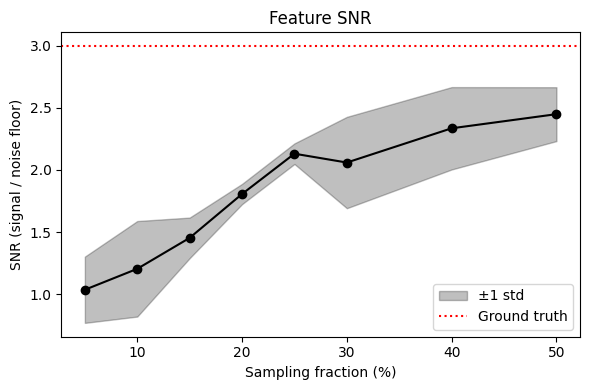

In [36]:
sparsities_pct = np.array(sparsity_levels) * 100
feat_means = np.array([np.mean(snr_feat_results[s]) for s in sparsity_levels])
feat_stds  = np.array([np.std(snr_feat_results[s])  for s in sparsity_levels])                                                                            

exp_pct = len(ri) / N * 100                                                                                                                               
                                        
fig, ax = plt.subplots(figsize=[6, 4])
ax.plot(sparsities_pct, feat_means, 'ko-')
ax.fill_between(sparsities_pct, feat_means - feat_stds, feat_means + feat_stds,
                alpha=0.25, color='k', label='±1 std')
ax.axhline(gt_snr_feat, linestyle=':', color='r', label='Ground truth')
ax.set_xlabel('Sampling fraction (%)')
ax.set_ylabel('SNR (signal / noise floor)')
ax.set_title('Feature SNR')
ax.legend()

plt.tight_layout()
plt.savefig(os.path.expanduser("~/Desktop/fig1/snr_vs_sparsity.pdf"), bbox_inches='tight')
plt.show()

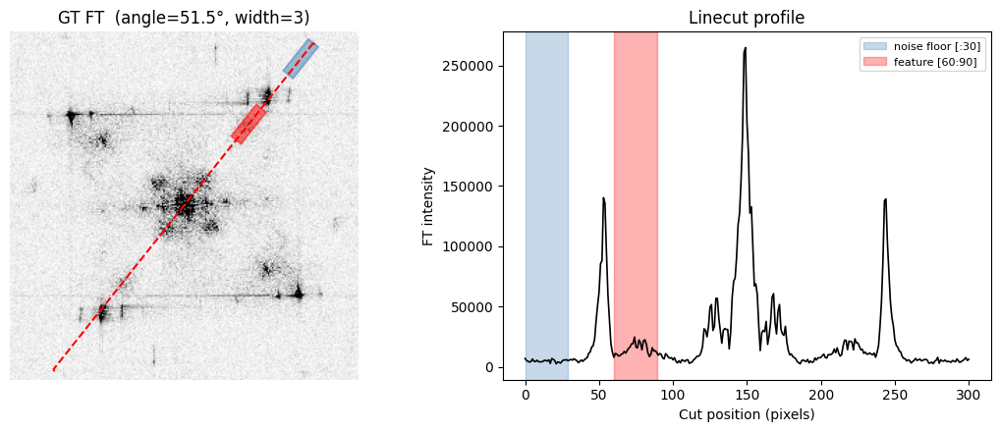

In [ ]:
to_plot = gt_ft                                                                                                                                           
H, W = np.shape(to_plot)
L = W // 2 * 1.2                                                                                                                                          
center = (np.array(np.shape(to_plot))[::-1] - 1) // 2
angle = 51.5 / 180 * np.pi
width = 3

p0 = center + np.array([L * np.cos(angle), L * np.sin(angle) * H / W])
p1 = center - np.array([L * np.cos(angle), L * np.sin(angle) * H / W])
p0_f = np.array([p0[0], (H - 1) - p0[1]])
p1_f = np.array([p1[0], (H - 1) - p1[1]])

fig, axes = plt.subplots(1, 2, figsize=[11, 4.5])

# --- left: FT image ---
c, s = np.mean(to_plot), np.std(to_plot)
axes[0].imshow(to_plot[::-1], clim=[0, c + 5*s], cmap=stmpy.cm.gray_r, origin='upper', rasterized=True)
axes[0].axis('off')
axes[0].set_title(f'GT FT  (angle={51.5}°, width={width})')
r, cut = stmpy.tools.linecut(to_plot[::-1], p0=p0_f, p1=p1_f, width=width, show=True, ax=axes[0], color='r')

n_pts = len(r)
ts = np.linspace(0, 1, n_pts)
xs_line = p0_f[0] + ts * (p1_f[0] - p0_f[0])
ys_line = p0_f[1] + ts * (p1_f[1] - p0_f[1])
theta = np.arctan2(p1_f[1] - p0_f[1], p1_f[0] - p0_f[0])
perp_x, perp_y = np.sin(theta), -np.cos(theta)
box_w = width * 3

def add_rect(ax, i_start, i_stop, color, alpha=0.5):
    corners = np.array([
        [xs_line[i_start] + box_w/2 * perp_x, ys_line[i_start] + box_w/2 * perp_y],
        [xs_line[i_start] - box_w/2 * perp_x, ys_line[i_start] - box_w/2 * perp_y],
        [xs_line[i_stop]  - box_w/2 * perp_x, ys_line[i_stop]  - box_w/2 * perp_y],
        [xs_line[i_stop]  + box_w/2 * perp_x, ys_line[i_stop]  + box_w/2 * perp_y],
    ])
    patch = MplPolygon(corners, closed=True, facecolor=color, edgecolor=color, alpha=alpha, lw=1.5)
    patch.set_rasterized(True)
    ax.add_patch(patch)

add_rect(axes[0], 0,  29, color='steelblue')
add_rect(axes[0], 60, 89, color='red')

# --- right: linecut profile ---
axes[1].plot(r, cut, 'k-', lw=1.2, rasterized=True)

noise_span = axes[1].axvspan(r[0],  r[29], alpha=0.3, color='steelblue', label='noise floor [:30]')
noise_span.set_rasterized(True)
feat_span  = axes[1].axvspan(r[60], r[89], alpha=0.3, color='red',       label='feature [60:90]')
feat_span.set_rasterized(True)

axes[1].set_xlabel('Cut position (pixels)')
axes[1].set_ylabel('FT intensity')
axes[1].set_title('Linecut profile')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.expanduser("~/Desktop/fig1/linecut_combined.pdf"), bbox_inches='tight')
plt.show()

In [34]:
en_snr_gt  = []
en_snr_rec = []

for i in range(len(d1_true.en)):
    en_snr_gt.append( ft_linecut_snr(d1_true.ft_c[i], angle_deg=51.5, signal_range=slice(60, 90)))
    en_snr_rec.append(ft_linecut_snr(d.ft_c[i],       angle_deg=51.5, signal_range=slice(60, 90)))

en_snr_gt  = np.array(en_snr_gt)
en_snr_rec = np.array(en_snr_rec)

AttributeError: 'Spy' object has no attribute 'ft_c'

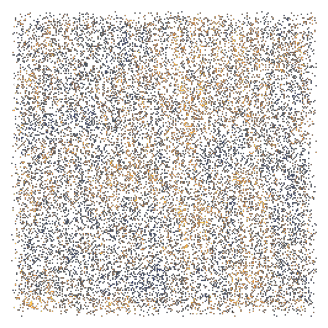

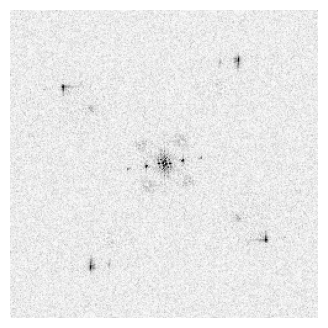

In [11]:
dfc.quick_plot(to_show[::-1], cmap=stmpy.cm.jackyPSD, clims=real_space_clims, thres=5, imgName="40 nm liy at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/sparse_sampling_realspace.pdf"), bbox_inches='tight')
to_show_fft = np.where(np.isnan(to_show), c_gt, to_show) # Need to check this.
dfc.quick_plot(st.fft(to_show_fft, zeroDC=True)[::-1], rspace=False, cmap=stmpy.cm.gray_r,
               clims=ft_clims, thres=5, imgName="ft 40 nm liy at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/sparse_sampling_ft.pdf"), bbox_inches='tight')

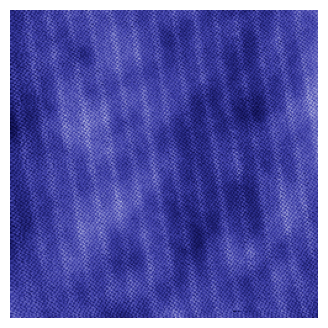

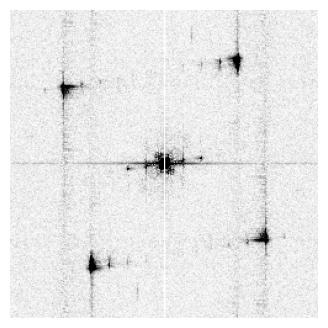

In [12]:
dfc.quick_plot(t.z[::-1], cmap=stmpy.cm.blue2, thres=5, imgName="40 nm topo", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/40_nm_topo_realspace.pdf"), bbox_inches='tight')
dfc.quick_plot(st.fft(t.z, zeroDC=True)[::-1], rspace=False, cmap=stmpy.cm.gray_r, thres=5, imgName="ft 40 nm topo", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/40_nm_topo_ft.pdf"), bbox_inches='tight')

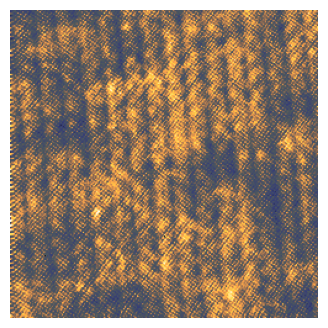

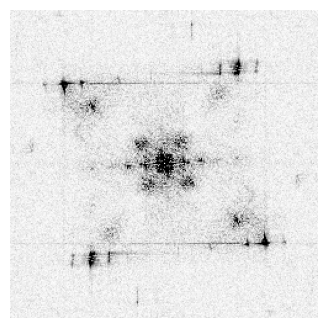

In [13]:
dfc.quick_plot(gt_fA[::-1], cmap=stmpy.cm.jackyPSD, thres=5, clims=real_space_clims, imgName="40 nm liy GT at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/ground_truth_realspace.pdf"), bbox_inches='tight')
dfc.quick_plot(st.fft(gt_fA, zeroDC=True)[::-1], rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, clims=ft_clims, imgName="ft 40 nm liy GT at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/ground_truth_ft.pdf"), bbox_inches='tight')


## Reconstruct the map

In [14]:
b_zeroDC = b - np.mean(b)
sigma =  1e-2 * np.linalg.norm(b_zeroDC) # % Desired ||Ax - b||_2
x, resid, grad,info = spg_bpdn(opA, b_zeroDC, sigma, iter_lim=1e5, verbosity=2e-1)
rec_bpdn = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
rec_bpdn_display = (rec_bpdn - np.nanmean(rec_bpdn)) / np.nanstd(rec_bpdn) * s_gt + c_gt
ft_bpdn = st.fft(rec_bpdn_display, zeroDC=True)


In [15]:
print(np.mean(ft_bpdn))
print(np.mean(c_ft))

6569.718604969354
8212.398810040078


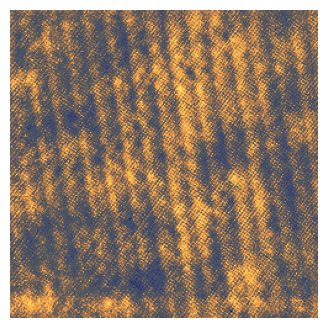

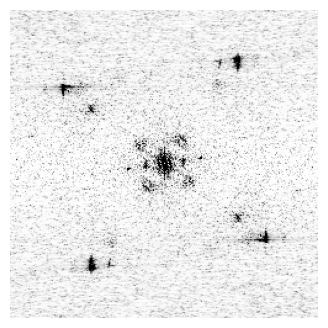

In [16]:

dfc.quick_plot(rec_bpdn_display[::-1], cmap=stmpy.cm.jackyPSD, thres=5, clims=real_space_clims,
               imgName="40 nm rec bpdn at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/recovered_realspace.pdf"), bbox_inches='tight')
dfc.quick_plot(ft_bpdn[::-1], rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, clims=ft_clims, imgName="ft 40 nm rec bpdn at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/recovered_ft.pdf"), bbox_inches='tight')

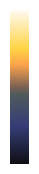

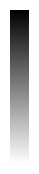

In [17]:
fig, ax = plt.subplots(figsize=[0.25, 2])
norm = mpl.colors.Normalize(vmin=real_space_clims[0], vmax=real_space_clims[1])
cb = mpl.colorbar.ColorbarBase(ax, cmap=stmpy.cm.jackyPSD, norm=norm, orientation='vertical')
cb.set_ticks([real_space_clims[0], real_space_clims[1]])
cb.set_ticks([])
cb.ax.tick_params(labelsize=10, length=0)
cb.outline.set_visible(False)
plt.savefig(os.path.expanduser("~/Desktop/fig1/colorbar_realspace.pdf"), bbox_inches='tight')

fig, ax = plt.subplots(figsize=[0.25, 2])
norm_ft = mpl.colors.Normalize(vmin=ft_clims[0], vmax=ft_clims[1])
cb_ft = mpl.colorbar.ColorbarBase(ax, cmap=stmpy.cm.gray_r, norm=norm_ft, orientation='vertical')
cb_ft.set_ticks([ft_clims[0], ft_clims[1]])
cb_ft.set_ticks([])
cb_ft.ax.tick_params(labelsize=10, length=0)
cb_ft.outline.set_visible(False)
plt.savefig(os.path.expanduser("~/Desktop/fig1/colorbar_ft.pdf"), bbox_inches='tight')

In [18]:
x,resid,grad,info = spg_bp(opA,b, verbosity=2)

# We need to transfer the z back to the real space
rec_bp = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
# dfc.display(test, z_topo*1e-15)


SPGL1
No. rows              :    15625     
No. columns           :    62500

Initial tau           : 0.00e+00     
Two-norm of b         : 8.30e+04

Optimality tol        : 1.00e-04     
Target objective      : 0.00e+00

Basis pursuit tol     : 1.00e-06     
Maximum iterations    :   156250

iterr      Objective   Relative Gap  Rel Error      gnorm   stepg   nnz_x   nnz_g     tau

    0  8.3004448e+04  0.0000000e+00   1.00e+00  4.133e+04     0.0       0       0  1.6670577e+05
    1  7.1433691e+04  1.9974122e+00   1.00e+00  3.552e+04    -0.6    3373       1               
    2  1.8548236e+04  1.7399052e+00   1.00e+00  8.353e+03     0.0      29       1               
    3  7.5976765e+03  9.7908732e-02   1.00e+00  7.568e+02     0.0      13       1               
    4  7.4263193e+03  1.9001456e-02   1.00e+00  3.924e+02     0.0       7       0               
    5  7.4261777e+03  1.6707637e-02   1.00e+00  3.848e+02     0.0       7       0  3.1001384e+05
    6  5.1609205e+03  1.0485748e

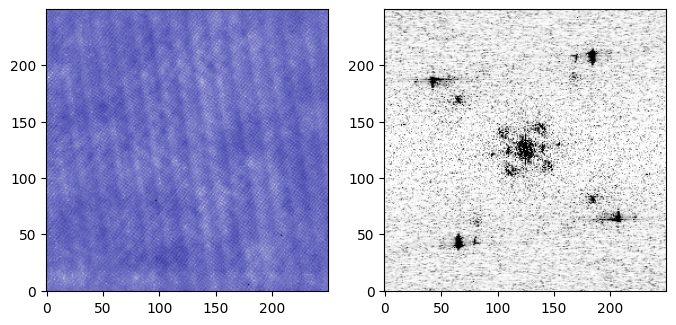

In [19]:
ft_bp = st.fft(rec_bp, zeroDC=True)

dfc.display(rec_bp)

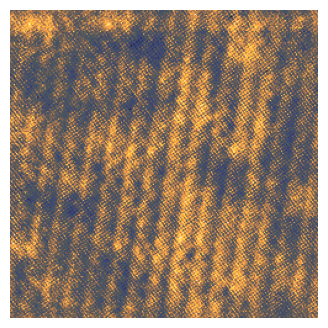

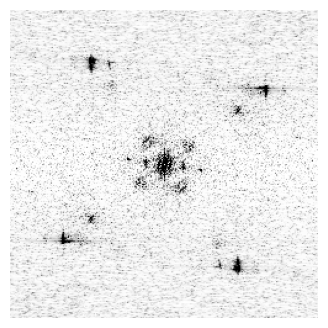

In [20]:
dfc.quick_plot(rec_bp, cmap=stmpy.cm.jackyPSD, thres=5,
               imgName="40 nm rec bp at -22 mV")
dfc.quick_plot(ft_bp, rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft 40 nm rec bp at -22 mV")

In [22]:
d.liy_rec = np.zeros_like(d1_true.LIY)

for i in range(len(d.en)):
    b = np.copy(d.LIY[i, 0]) * 1e15
    sigma =  1e-2 #     % Desired ||Ax - b||_2
    x, resid, grad,info = spg_bpdn(opA, b, sigma, iter_lim=1e5, verbosity=2e-1)
    d.liy_rec[i] = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]

# Drift correction

## Before reconstruction

The coordinates of the Bragg peaks are:
array([[207,  63],
       [ 43, 187],
       [185, 210],
       [ 65,  40]])

The coordinates of the Q vectors are:
array([[ 83, -61],
       [-81,  63],
       [ 61,  86],
       [-59, -84]])


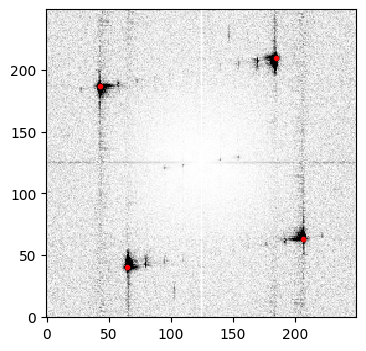

In [23]:
bp_before = dfc.findBraggs(t.z, r=0.2, show=True)

In [24]:
bpc1_before = dfc.generate_bp(t.z, bp=bp_before, orient=None)
bpc1_before

array([[ 66,  41],
       [ 41, 182],
       [182, 207],
       [207,  66]])

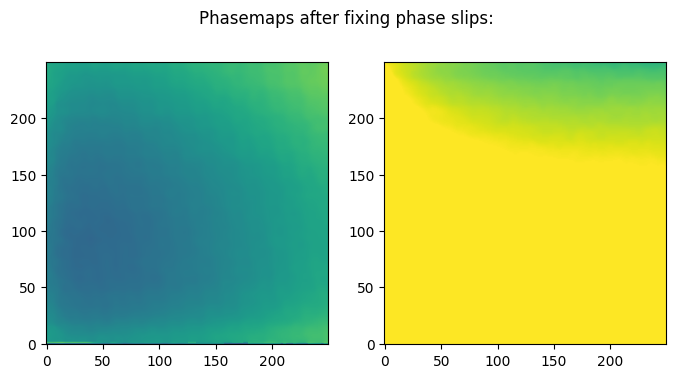

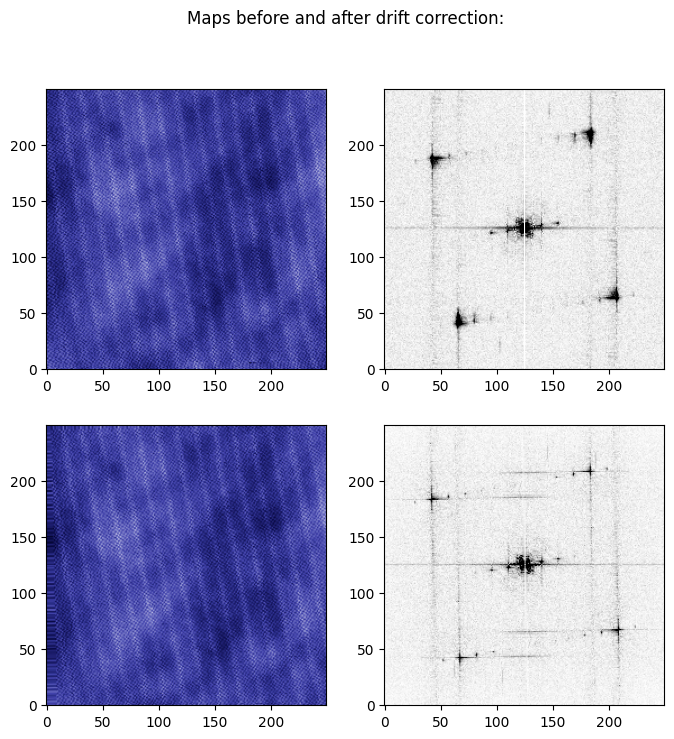

In [25]:
z1_before, p1_before = dfc.find_drift_parameter(t.z, bp_c=bpc1_before, sigma=13,
                                                cut2=None, show=True)

The coordinates of the Bragg peaks are:
array([[208,  67],
       [ 42, 183],
       [ 67,  42],
       [183, 208]])

The coordinates of the Q vectors are:
array([[ 84, -57],
       [-82,  59],
       [-57, -82],
       [ 59,  84]])


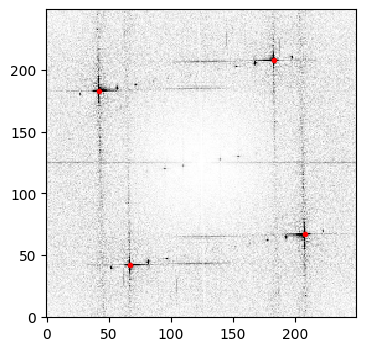

In [26]:
bp2_before = dfc.findBraggs(z1_before, r=0.2, show=True)

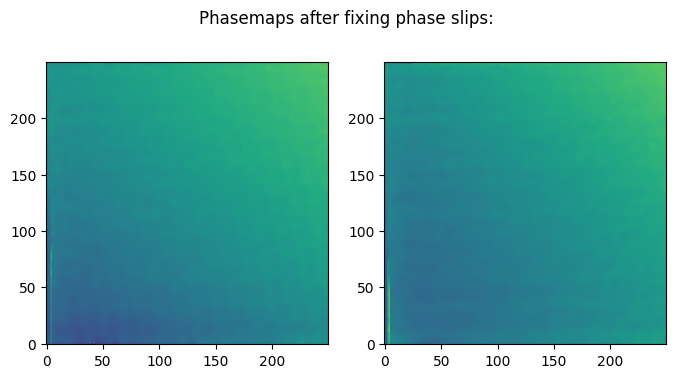

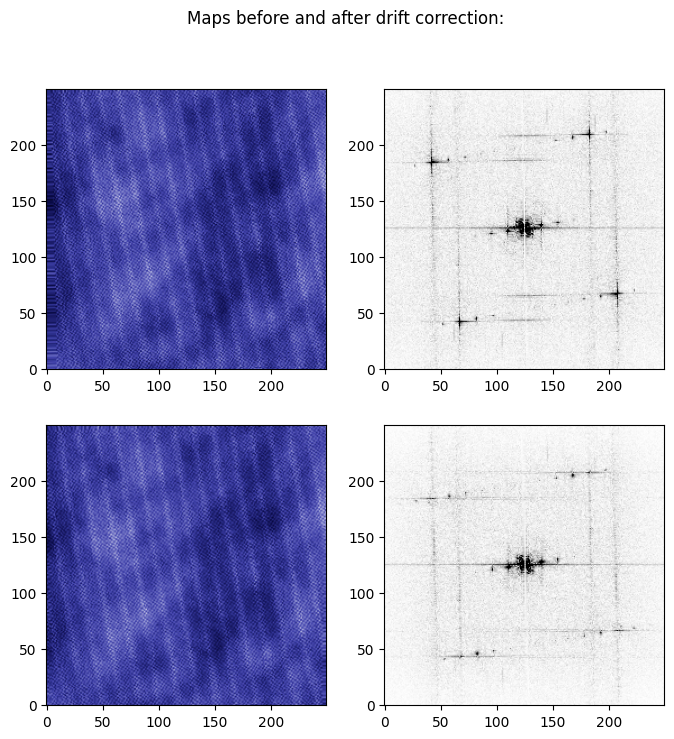

In [27]:
z2_before, p2_before = dfc.find_drift_parameter(z1_before, bp_c=bp2_before,
                                                sigma=17, show=True)

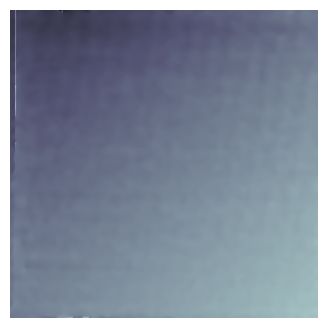

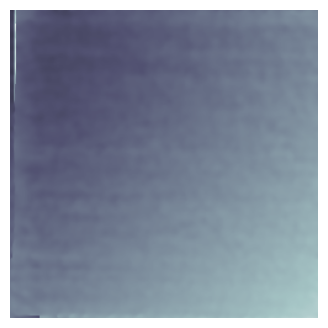

In [28]:
dfc.quick_plot(p2_before['phix'], cmap=stmpy.cm.bone,
               thres=5, imgName="40 nm topo dfc before phix", rasterized=True)

plt.savefig(os.path.expanduser("~/Desktop/fig1/draftxx.pdf"), bbox_inches='tight')

dfc.quick_plot(p2_before['phiy'], cmap=stmpy.cm.bone,
               thres=5, imgName="40 nm topo dfc before phiy", rasterized=True)

plt.savefig(os.path.expanduser("~/Desktop/fig1/draftyy.pdf"), bbox_inches='tight')

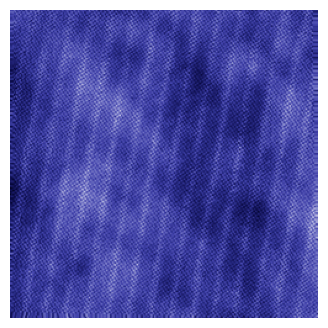

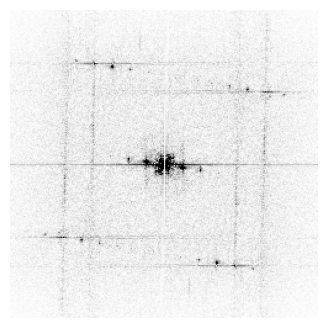

In [31]:
dfc.quick_plot(z2_before, cmap=stmpy.cm.blue2,
               thres=5, imgName="40 nm topo dfc before")

dfc.quick_plot(st.fft(z2_before,zeroDC=True), rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft 40 nm topo dfc before")

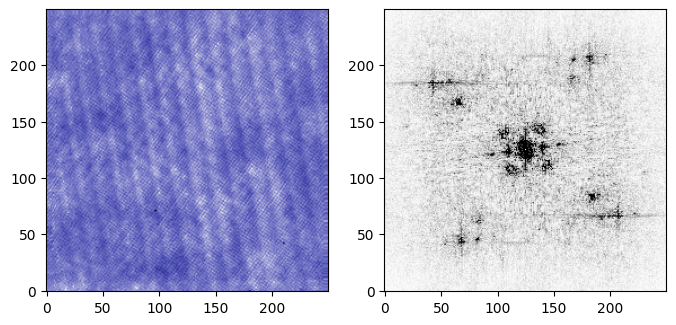

In [32]:
liy_temp = dfc.apply_drift_parameter(rec_bpdn, p1_before)

rec_bpdn_before = dfc.apply_drift_parameter(liy_temp, p2_before)

dfc.display(rec_bpdn_before)

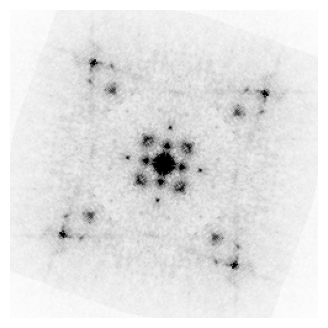

In [34]:
ft_bpdn_before = st.fft(rec_bpdn_before, zeroDC=True)
dfc.quick_plot(st.symmetrize(ft_bpdn_before, bp=bp2_before[0], n=4, mirrorOnly=False),
               thres=5, rspace=False)

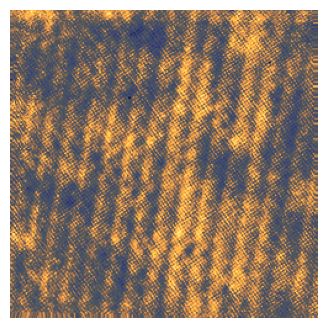

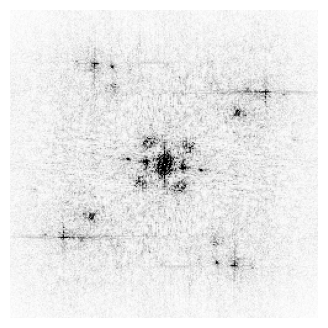

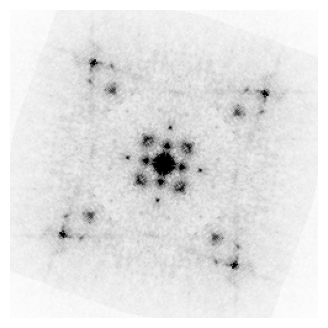

In [35]:
dfc.quick_plot(rec_bpdn_before, cmap=stmpy.cm.jackyPSD, thres=5,
               imgName="40 nm rec bpdn dfc before at -22 mV")
dfc.quick_plot(ft_bpdn_before, rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft 40 nm rec bpdn dfc before at -22 mV")
dfc.quick_plot(st.symmetrize(ft_bpdn_before, bp=bp2_before[0], n=4, mirrorOnly=False), rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft symm 40 nm rec bpdn dfc before at -22 mV")

In [32]:
liy_temp = dfc.apply_drift_parameter(d.liy_rec, p1_before)

d.liy_c = dfc.apply_drift_parameter(liy_temp, p2_before)

# dfc.display(rec_bp_before)

In [33]:
d.ft_c = st.fft(d.liy_c, zeroDC=True)
d.ft_symm = st.symmetrize(d.ft_c, bp=bp2_before[0], n=4, mirrorOnly=False)
# dfc.quick_plot(st.symmetrize(ft_c, bp=bp2[0], n=4, mirrorOnly=False),
#                thres=5, rspace=False)

/Users/marcosjohnsonnoya/Coding/SparseSampling/.venv/lib/python3.11/site-packages/stmpy/driftcorr.py:1916: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=[fs, fs])


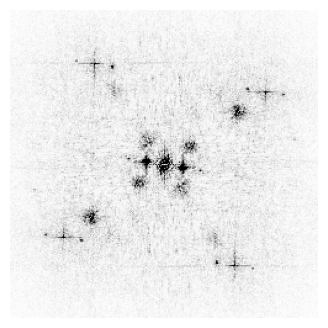

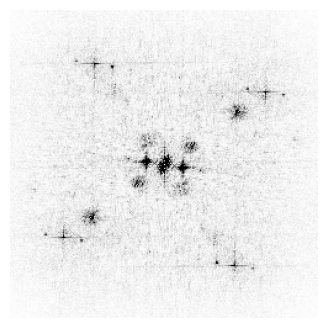

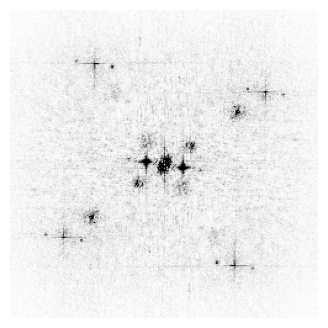

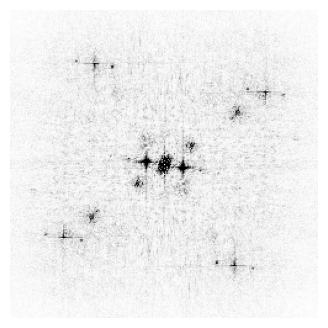

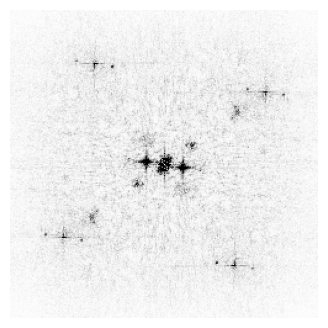

...

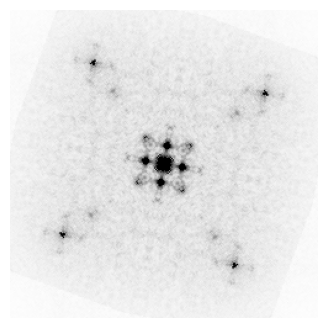

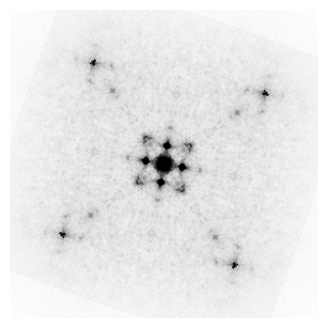

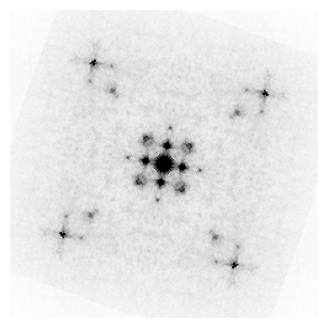

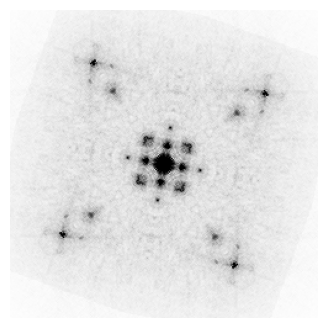

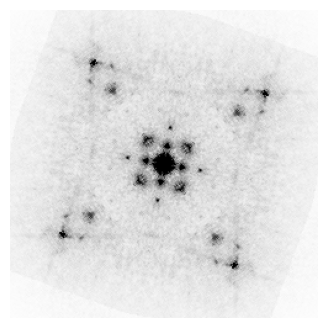

In [34]:
dfc.quick_show_single(d.ft_c, en=d.en*1e3, qscale=1.2, saveon=True, imgName="40 nm ft rec bpdn corr")
dfc.quick_show_single(d.ft_symm, en=d.en*1e3, qscale=1.2, saveon=True, imgName="40 nm ft rec bpdn corr symm")

## Drift correction after reconstruction

The coordinates of the Bragg peaks are:
array([[207,  63],
       [ 43, 187],
       [ 65,  41],
       [185, 209]])

The coordinates of the Q vectors are:
array([[ 83, -61],
       [-81,  63],
       [-59, -83],
       [ 61,  85]])


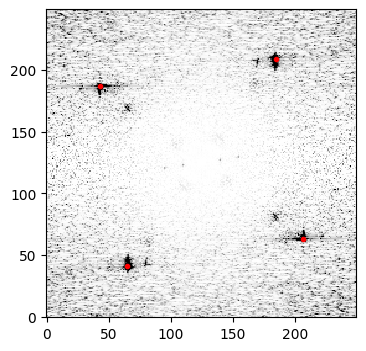

In [36]:
bpdn_after = dfc.findBraggs(rec_bpdn, r=0.5, min_dist=20, show=True)

In [37]:
bpc1_after = dfc.generate_bp(rec_bpdn, bp=bpdn_after, orient=None)
bpc1_after

array([[ 65,  41],
       [ 41, 183],
       [183, 207],
       [207,  65]])

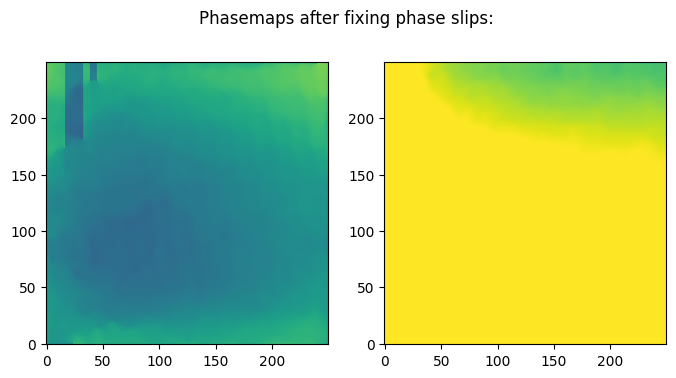

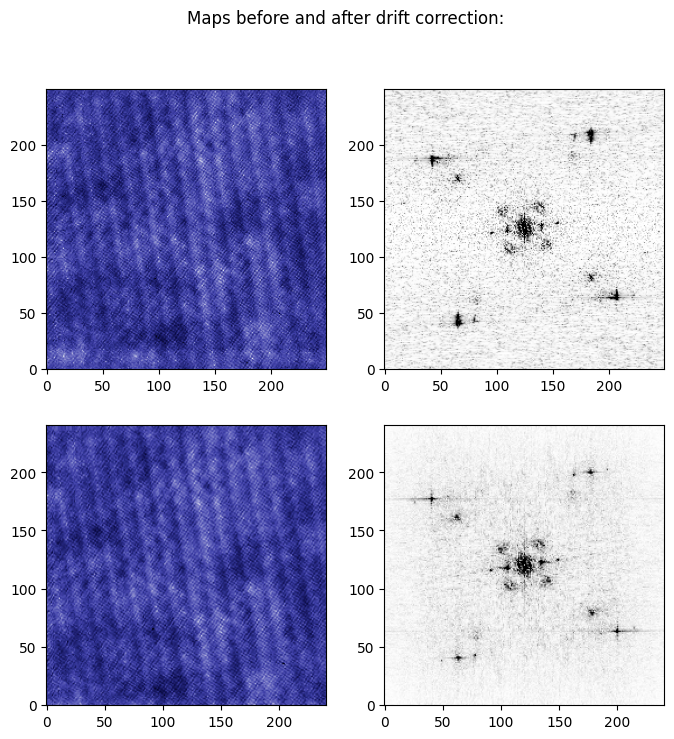

In [38]:
z1_after, p1_after = dfc.find_drift_parameter(rec_bpdn, bp_c=bpc1_after, sigma=10,
                                                cut2=[9,0,9,0], show=True)

The coordinates of the Bragg peaks are:
array([[200,  63],
       [ 40, 177],
       [ 63,  40],
       [177, 200]])

The coordinates of the Q vectors are:
array([[ 80, -57],
       [-80,  57],
       [-57, -80],
       [ 57,  80]])


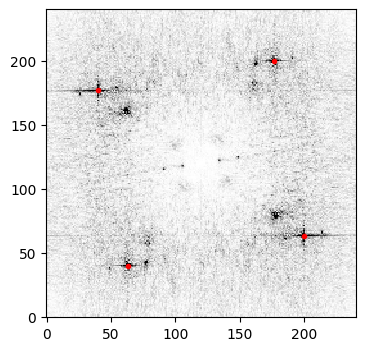

In [39]:
bp2_after = dfc.findBraggs(z1_after, r=0.2, show=True)

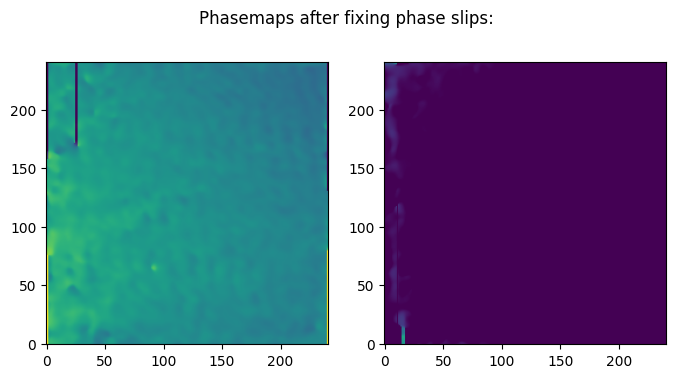

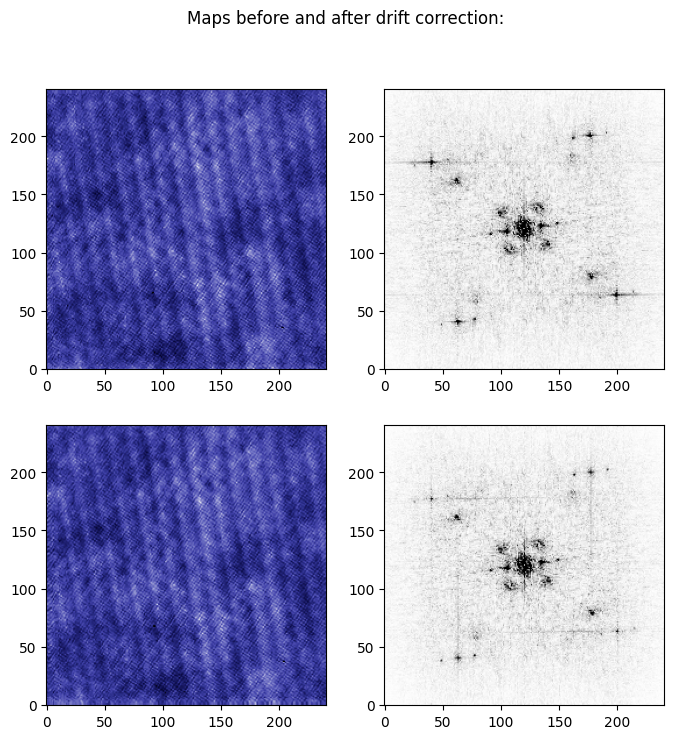

In [40]:
z2_after, p2_after = dfc.find_drift_parameter(z1_after, bp_c=bp2_after,
                                            sigma=13, show=True)

In [41]:
liy_temp = dfc.apply_drift_parameter(rec_bpdn, p1_after)

rec_bpdn_after = dfc.apply_drift_parameter(liy_temp, p2_after)

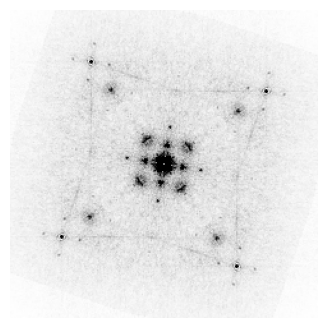

In [42]:
ft_bpdn_after = st.fft(rec_bpdn_after, zeroDC=True)
dfc.quick_plot(st.symmetrize(ft_bpdn_after, bp=bp2_after[0], n=4, mirrorOnly=False),
               thres=5, rspace=False)

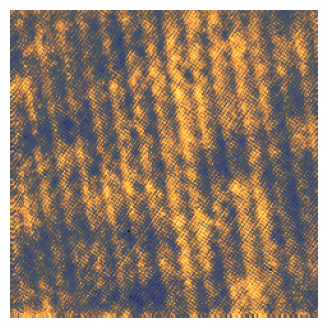

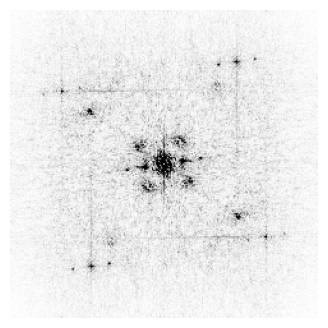

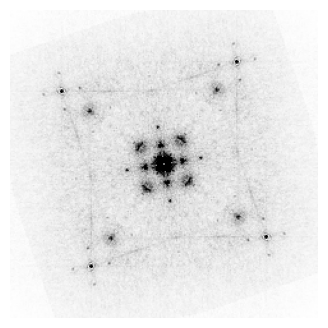

In [47]:
dfc.quick_plot(rec_bpdn_after[::-1], cmap=stmpy.cm.jackyPSD, thres=5,
               imgName="40 nm rec bpdn dfc after at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/40 nm rec bpdn dfc after at -22 mV.pdf"), bbox_inches='tight')
dfc.quick_plot(ft_bpdn_after[::-1], rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft 40 nm rec bpdn dfc after at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/ft 40 nm rec bpdn dfc after at -22 mV.pdf"), bbox_inches='tight')
dfc.quick_plot(st.symmetrize(ft_bpdn_after, bp=bp2_after[0], n=4, mirrorOnly=False)[::-1], rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft symm 40 nm rec bpdn dfc after at -22 mV", rasterized=True)
plt.savefig(os.path.expanduser("~/Desktop/fig1/ft symm 40 nm rec bpdn dfc after at -22 mV.pdf"), bbox_inches='tight')

## Ground truth

In [ ]:
z = st.lineSubtract(d1_true.Z, 1)

The coordinates of the Bragg peaks are:
array([[207,  60],
       [ 43, 190],
       [ 66,  51],
       [184, 199]])

The coordinates of the Q vectors are:
array([[ 83, -64],
       [-81,  66],
       [-58, -73],
       [ 60,  75]])


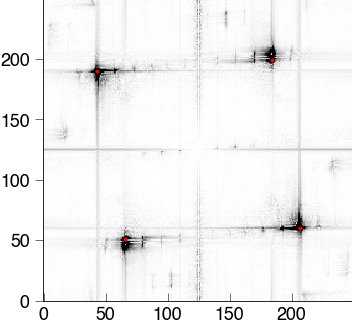

In [ ]:
bp = dfc.findBraggs(z, r=0.2, min_dist=10, show=True)

In [ ]:
bpc1 = dfc.generate_bp(z, bp=bp, orient=None)
bpc1

array([[ 63,  47],
       [ 47, 185],
       [185, 201],
       [201,  63]])

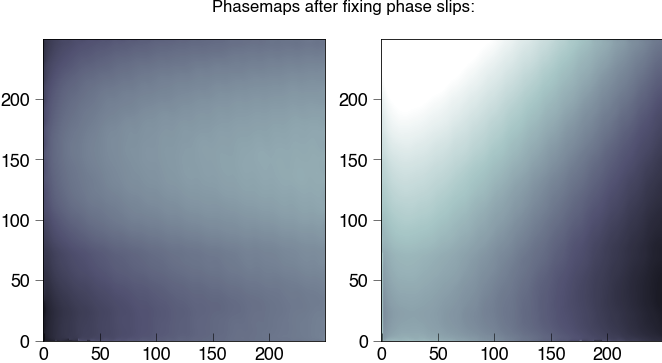

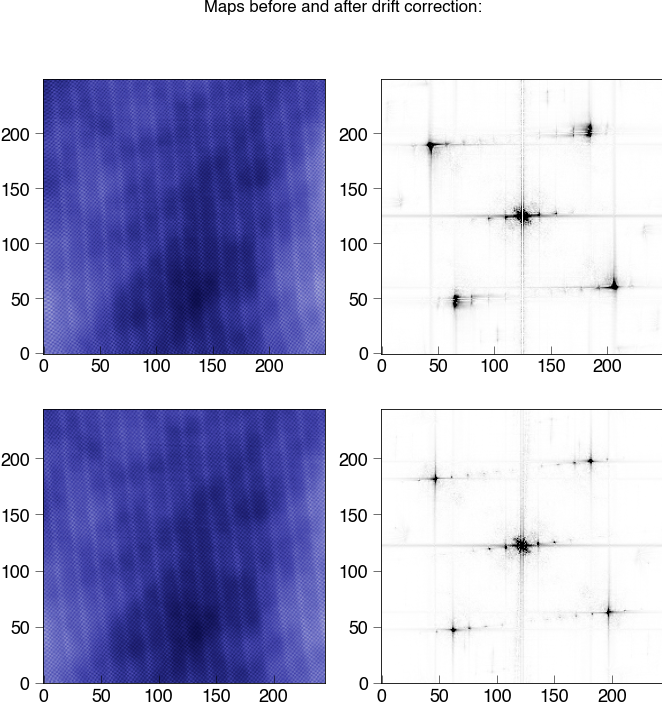

In [ ]:
z1, p1 = dfc.find_drift_parameter(z, bp_c=bpc1, sigma=15,
                                                cut2=[5,0,5,0], show=True)

The coordinates of the Bragg peaks are:
array([[ 62,  47],
       [182, 197],
       [197,  62],
       [ 47, 182]])

The coordinates of the Q vectors are:
array([[-60, -75],
       [ 60,  75],
       [ 75, -60],
       [-75,  60]])


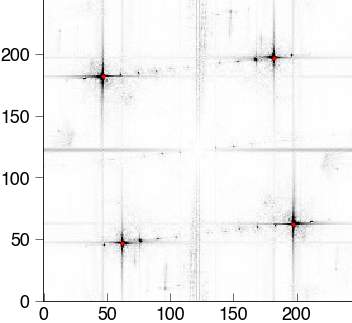

In [ ]:
bp2 = dfc.findBraggs(z1, r=0.2, show=True)

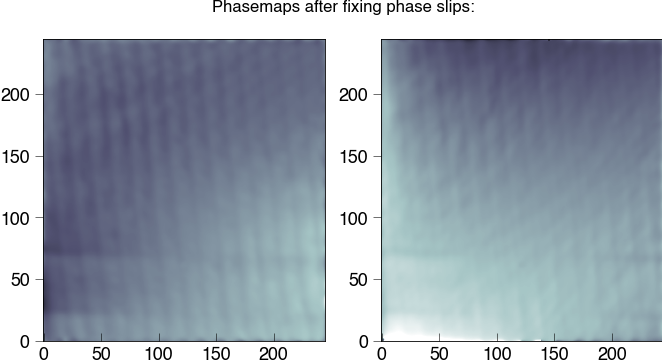

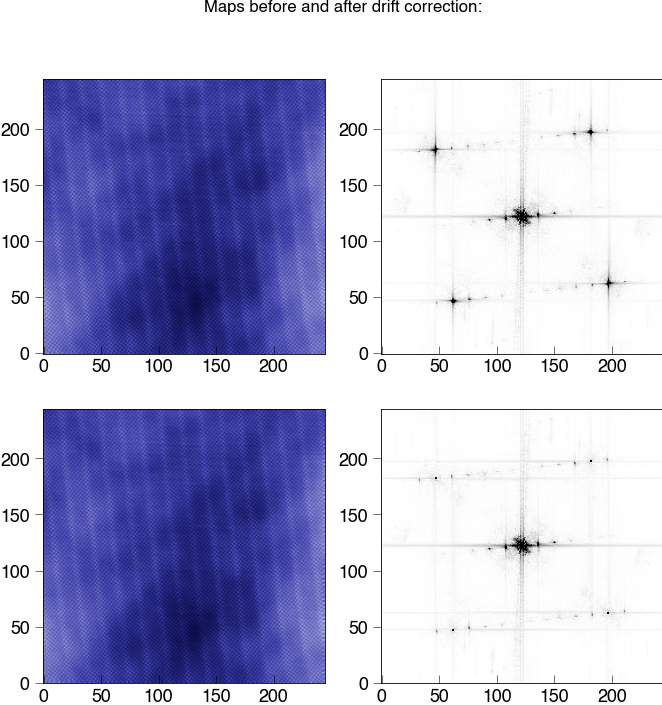

In [ ]:
z2, p2 = dfc.find_drift_parameter(z1, bp_c=bp2,
                                                sigma=17, show=True)

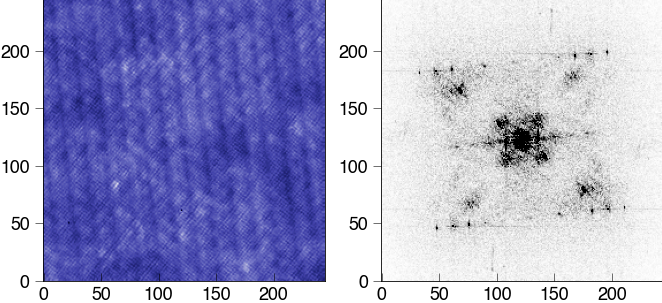

In [ ]:
liy_temp = dfc.apply_drift_parameter(d1_true.LIY[-1], p1)

liy_c = dfc.apply_drift_parameter(liy_temp, p2)

dfc.display(liy_c)

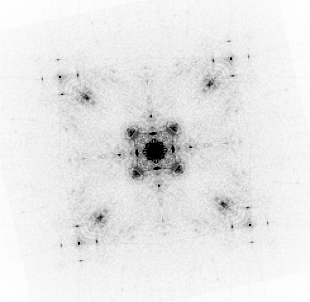

In [ ]:
ft_c = st.fft(liy_c, zeroDC=True)
dfc.quick_plot(st.symmetrize(ft_c, bp=bp2[0], n=4, mirrorOnly=False),
               thres=5, rspace=False)

In [ ]:
dfc.quick_plot(liy_c, cmap=stmpy.cm.jackyPSD, thres=5,
               imgName="40 nm liy corr at -22 mV")
dfc.quick_plot(ft_c, rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft 40 nm liy corr at -22 mV")
dfc.quick_plot(st.symmetrize(ft_c, bp=bp2[0], n=4, mirrorOnly=False), rspace=False, cmap=stmpy.cm.gray_r,
               thres=5, imgName="ft symm 40 nm liy corr at -22 mV")

NameError: name 'liy_c' is not defined

In [ ]:
liy1 = st.nsigma_local(d1_true.LIY)
shape(liy1)

(12, 250, 250)

In [ ]:
liy_temp = dfc.apply_drift_parameter(liy1, p1)

d1_true.liy_c = dfc.apply_drift_parameter(liy_temp, p2)

# dfc.display(d1_true.liy_c)

In [ ]:
d1_true.ft_c = st.fft(d1_true.liy_c, zeroDC=True)
d1_true.ft_symm = st.symmetrize(d1_true.ft_c, bp=bp2[0], n=4, mirrorOnly=False)
# dfc.quick_plot(st.symmetrize(ft_c, bp=bp2[0], n=4, mirrorOnly=False),
#                thres=5, rspace=False)

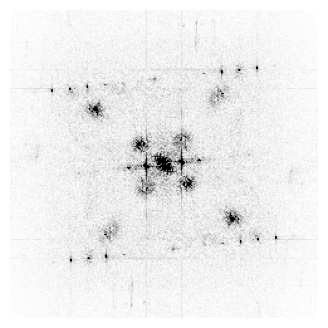

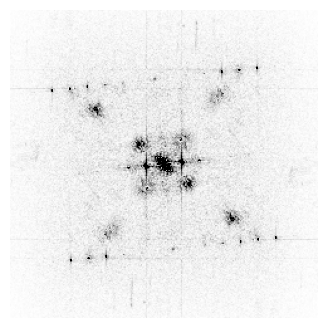

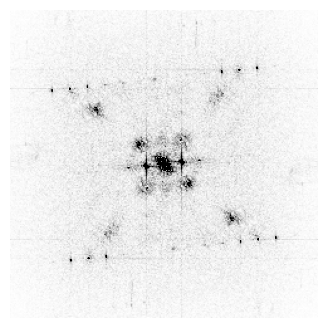

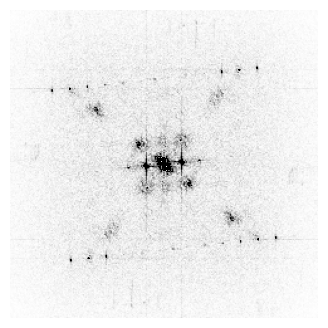

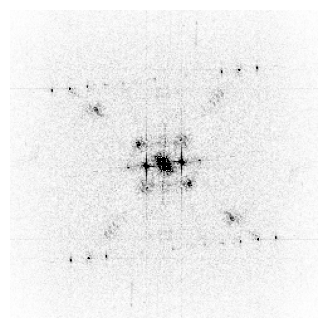

...

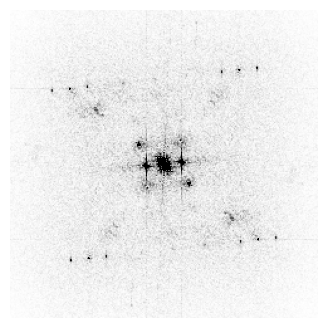

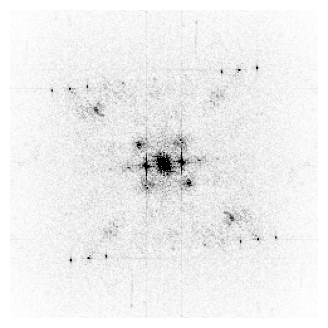

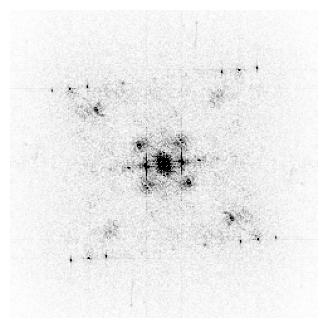

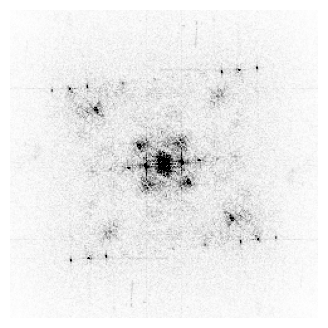

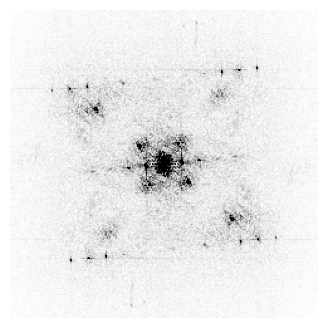

In [ ]:
dfc.quick_show_single(d1_true.ft_c, en=d1_true.en*1e3, qscale=1.2, saveon=True, imgName="40 nm ft liy corr")

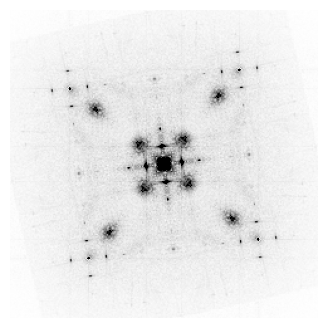

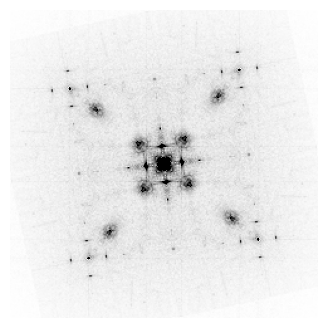

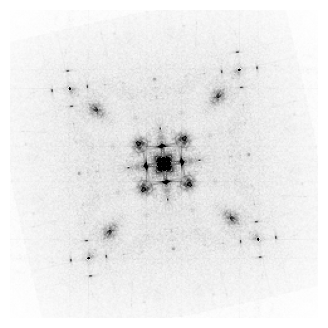

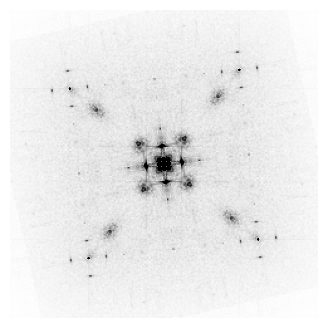

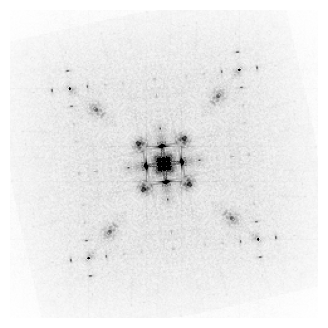

...

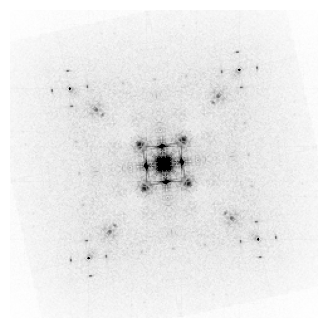

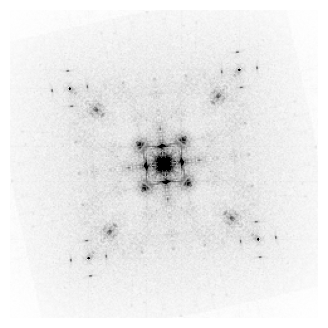

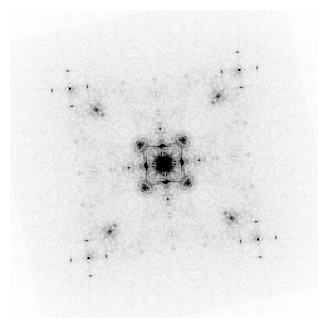

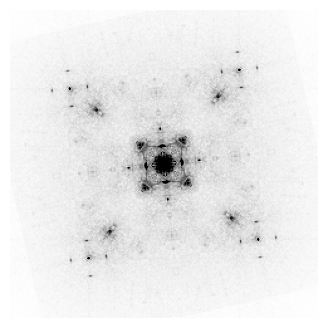

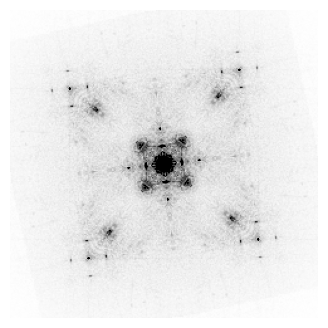

In [ ]:
dfc.quick_show_single(d1_true.ft_symm, en=d1_true.en*1e3, qscale=1.2, saveon=True, imgName="40 nm ft liy corr symm")

# Compare the ground truth with the reconstructed map

## Square residual

In [ ]:
liy_c = copy(d1_true.liy_c)
liy_ft = copy(d1_true.ft_c)

rec_c = copy(d.liy_c)
rec_ft = copy(d.ft_c)

AttributeError: 'Spy' object has no attribute 'liy_c'

## Signal to noise ratio

In [ ]:
# res = stmpy.io.Spy()

# res.liy_c = liy_c
# res.rec_c = rec_c

# stmpy.save(res, 'res after dfc.spy')

In [ ]:
liy_c = copy(d1_true.liy_c)
liy_ft = copy(d1_true.ft_c)

rec_c = copy(d.liy_c)
rec_ft = copy(d.ft_c)

In [ ]:
liy_topo = mean(liy_c, axis=0)
rec_topo = mean(rec_c, axis=0)

The coordinates of the Bragg peaks are:
array([[197,  62],
       [ 47, 182],
       [ 62,  47],
       [182, 197]])

The coordinates of the Q vectors are:
array([[ 75, -60],
       [-75,  60],
       [-60, -75],
       [ 60,  75]])


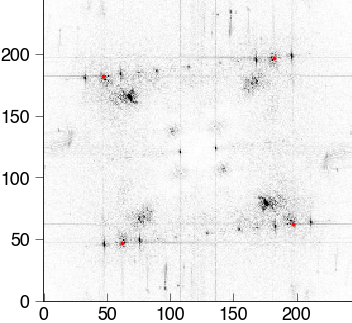

In [ ]:
bp_liy = dfc.findBraggs(liy_topo, r=0.2, show=True)

The coordinates of the Bragg peaks are:
array([[ 65,  41],
       [175, 199],
       [ 41, 175],
       [199,  65]])

The coordinates of the Q vectors are:
array([[-55, -79],
       [ 55,  79],
       [-79,  55],
       [ 79, -55]])


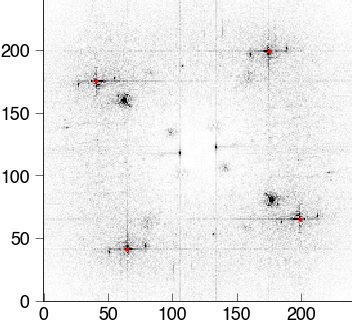

In [ ]:
bp_rec = dfc.findBraggs(rec_topo, r=0.2, show=True)

In [20]:
# take linecut -- also works for non-square dataset
# d.fft_c = st.fft(d.liy_c, zeroDC=True)
to_cut = liy_ft
# Here are the angles for the linecuts
angles = []
offset = 0 # first angle of linecut in the unit of degrees
width = 3 # width to average the linecut

# to_plot = np.mean(to_cut, axis=0)
to_plot = copy(liy_ft)[-1]
H, W = np.shape(to_plot)

# This is the length of the linecut
L = W // 2 * 1.2
center = (np.array(np.shape(to_plot))[::-1]-1) // 2

# for i in range(4):
#     angles.append(offset/180*np.pi+i*np.pi/4)

colors = stmpy.cm.rainbow(np.linspace(0, 1, len(angles)))

c = np.mean(to_plot)
s = np.std(to_plot)

figure(figsize=[4,4])
imshow(to_plot, clim=[0, c+5*s], cmap=stmpy.cm.gray_r)

rs = []
cuts = []
angles = 51.5/180*np.pi

# for i in range(len(angles)):
p0 = center + np.array([L * cos(angles), L * sin(angles) * H / W])
p1 = center - np.array([L * cos(angles), L * sin(angles) * H / W])

r1, cut1 = stmpy.tools.linecut(to_cut, p0=p0, p1=p1, width=width, show=True, ax=gca(), color='r')
axis('off')
gca().set_aspect(1)
xlim(0, len(to_plot))
ylim(0, len(to_plot))
# rs.append(r)
# cuts.append(cut)
# savefig('snr linecut scheme 40 nm liy.png', dpi=400, bbox_inches='tight', pad_inches=0)

NameError: name 'liy_ft' is not defined

(0.0, 241.0)

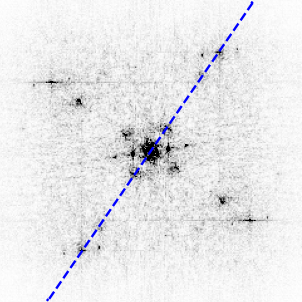

In [ ]:
# take linecut -- also works for non-square dataset
# d.fft_c = st.fft(d.liy_c, zeroDC=True)
to_cut = rec_ft
# Here are the angles for the linecuts
angles = []
offset = 0 # first angle of linecut in the unit of degrees
width = 3 # width to average the linecut

# to_plot = np.mean(to_cut, axis=0)
to_plot = copy(rec_ft)[-1]
H, W = np.shape(to_plot)

# This is the length of the linecut
L = W // 2 * 1.2
center = (np.array(np.shape(to_plot))[::-1]-1) // 2

# for i in range(4):
#     angles.append(offset/180*np.pi+i*np.pi/4)

colors = stmpy.cm.rainbow(np.linspace(0, 1, len(angles)))

c = np.mean(to_plot)
s = np.std(to_plot)

figure(figsize=[4,4])
imshow(to_plot, clim=[0, c+5*s], cmap=stmpy.cm.gray_r)

rs = []
cuts = []
angles = 55.5/180*np.pi

# for i in range(len(angles)):
p0 = center + np.array([L * cos(angles), L * sin(angles) * H / W])
p1 = center - np.array([L * cos(angles), L * sin(angles) * H / W])

r2, cut2 = stmpy.tools.linecut(to_cut, p0=p0, p1=p1, width=width, show=True, ax=gca(), color='b')
axis('off')
gca().set_aspect(1)
xlim(0, len(to_plot))
ylim(0, len(to_plot))

# rs.append(r)
# cuts.append(cut)
# savefig('snr linecut scheme 40 nm rec.png', dpi=400, bbox_inches='tight', pad_inches=0)

([], <a list of 0 Text major ticklabel objects>)

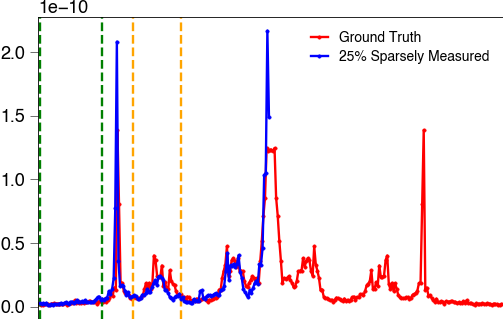

In [ ]:
x1 = linspace(-1.2, 1.2, num=len(r1))
x2 = linspace(-1.19, 1.19, num=len(r2))

figure(figsize=[6,4])
plot(x1, cut1[0], 'r.-', label='Ground Truth')
axvline(x1[40], linestyle='--', color='green')
axvline(-1.19, linestyle='--', color='green')

axvline(x1[60], linestyle='--', color='orange')
axvline(x1[90], linestyle='--', color='orange')
# figure(figsize=[6,4])
plot(x2[:len(x2)//2], cut2[0][:len(x2)//2] * sum(cut1[0])/sum(cut2[0]), 'b.-', label='25% Sparsely Measured')
# axvline(x2[30], linestyle='--', color='blue')
# axvline(x2[60], linestyle='--', color='orange')
# axvline(x2[90], linestyle='--', color='orange')
legend()

xlim(-1.2, 1.2)
xticks([])
# savefig('snr linecut scheme 40 nm comparison 2.png', dpi=400, bbox_inches='tight', pad_inches=0)

In [ ]:
liy_snr_bp = []
for i in range(len(cut1)):
    noise = mean(cut1[i][:30])
    signal = mean(cut1[i][45:55])
    liy_snr_bp.append(signal / noise)

rec_snr_bp = []
for i in range(len(cut2)):
    noise = mean(cut2[i][:30])
    signal = mean(cut2[i][45:55])
    rec_snr_bp.append(signal / noise)

In [ ]:
liy_snr = []
for i in range(len(cut1)):
    noise = mean(cut1[i][:30])
    signal = mean(cut1[i][60:90])
    liy_snr.append(signal / noise)

rec_snr = []
for i in range(len(cut2)):
    noise = mean(cut2[i][:30])
    signal = mean(cut2[i][60:90])
    rec_snr.append(signal / noise)

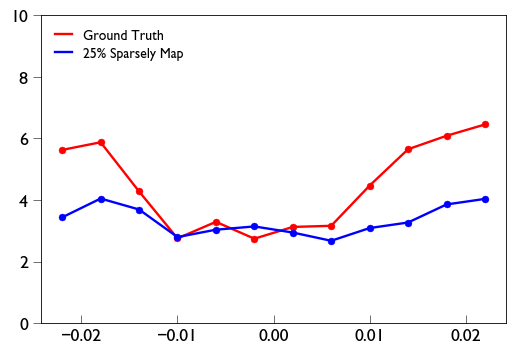

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_snr, 'r', label='Ground Truth')
plot(d.en, liy_snr, 'ro',)

plot(d.en, rec_snr, 'b', label='25% Sparsely Map')
plot(d.en, rec_snr, 'bo',)
ylim(0, 10)
legend(loc='upper left')

savefig('../figures/snr linecut scheme 40 nm comparison.png', dpi=400, bbox_inches='tight', pad_inches=0)

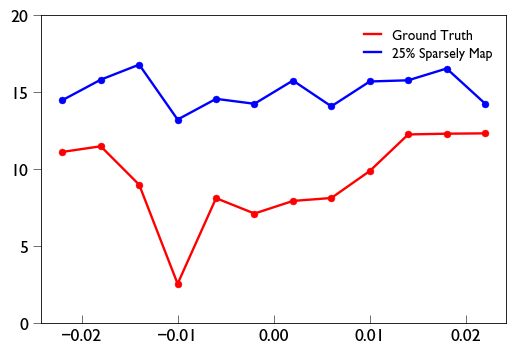

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_snr_bp, 'r', label='Ground Truth')
plot(d.en, liy_snr_bp, 'ro',)

plot(d.en, rec_snr_bp, 'b', label='25% Sparsely Map')
plot(d.en, rec_snr_bp, 'bo',)
ylim(0, 20)
yticks([0, 5, 10, 15, 20])
legend(loc='upper right')

savefig('../figures/snr linecut scheme 40 nm bp comparison.png', dpi=400, bbox_inches='tight', pad_inches=0)

In [ ]:
d1_true.header

{'Grid dim': '"250 x 250"',
 'Grid settings': '-5.040688E-8;-5.187596E-8;4.000000E-8;4.000000E-8;2.572162E+1',
 'Filetype': 'Linear',
 'Sweep Signal': '"Bias (V)"',
 'Fixed parameters': '"Sweep Start;Sweep End"',
 'Experiment parameters': '"X (m);Y (m);Z (m);Z offset (m);Settling time (s);Integration time (s);Z-Ctrl hold;Final Z (m);Scan:Current (A);Scan:Z (m)"',
 '# Parameters (4 byte)': '12',
 'Experiment size (bytes)': '192',
 'Points': '12',
 'Channels': '"Current (A);Bias (V);LI Demod 1 X (A);LI Demod 1 Y (A)"',
 'Delay before measuring (s)': '10.000000E-3',
 'Experiment': '"Grid Spectroscopy"',
 'Start time': '"04.09.2022 23:41:48"',
 'End time': '"05.09.2022 14:26:00"',
 'User': '',
 'Comment': '"BSCCO, 100mV/70pA,  2.5 mV excit, 22 mV to -22 mv with 12 pts, 40x40 nm with 250x250 pts"',
 'Bias>Bias (V)': '100E-3',
 'Bias>Calibration (V/V)': '1E+0',
 'Bias>Offset (V)': '-1.4E-3',
 'Bias Spectroscopy>Sweep Start (V)': '22E-3',
 'Bias Spectroscopy>Sweep End (V)': '-22E-3',
 'Bias S

In [ ]:
liy_symm = copy(d1_true.ft_symm)
rec_symm = copy(d.ft_symm)

(0.0, 245.0)

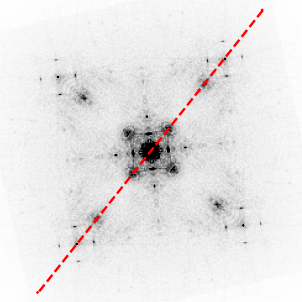

In [ ]:
# take linecut -- also works for non-square dataset
# d.fft_c = st.fft(d.liy_c, zeroDC=True)
to_cut = liy_symm
# Here are the angles for the linecuts
angles = []
offset = 0 # first angle of linecut in the unit of degrees
width = 3 # width to average the linecut

# to_plot = np.mean(to_cut, axis=0)
to_plot = copy(liy_symm)[-1]
H, W = np.shape(to_plot)

# This is the length of the linecut
L = W // 2 * 1.2
center = (np.array(np.shape(to_plot))[::-1]-1) // 2

# for i in range(4):
#     angles.append(offset/180*np.pi+i*np.pi/4)

colors = stmpy.cm.rainbow(np.linspace(0, 1, len(angles)))

c = np.mean(to_plot)
s = np.std(to_plot)

figure(figsize=[4,4])
imshow(to_plot, clim=[0, c+5*s], cmap=stmpy.cm.gray_r)

rs = []
cuts = []
angles = 51.5/180*np.pi

# for i in range(len(angles)):
p0 = center + np.array([L * cos(angles), L * sin(angles) * H / W])
p1 = center - np.array([L * cos(angles), L * sin(angles) * H / W])

r1_symm, cut1_symm = stmpy.tools.linecut(to_cut, p0=p0, p1=p1, width=width, show=True, ax=gca(), color='r')
axis('off')
gca().set_aspect(1)
xlim(0, len(to_plot))
ylim(0, len(to_plot))
# rs.append(r)
# cuts.append(cut)
# savefig('snr linecut scheme 40 nm liy symm.png', dpi=400, bbox_inches='tight', pad_inches=0)

(0.0, 241.0)

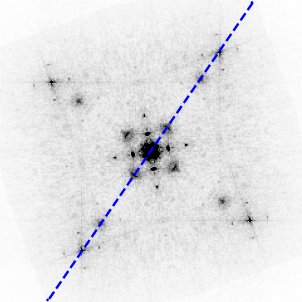

In [ ]:
# take linecut -- also works for non-square dataset
# d.fft_c = st.fft(d.liy_c, zeroDC=True)
to_cut = rec_symm
# Here are the angles for the linecuts
angles = []
offset = 0 # first angle of linecut in the unit of degrees
width = 3 # width to average the linecut

# to_plot = np.mean(to_cut, axis=0)
to_plot = copy(rec_symm)[-1]
H, W = np.shape(to_plot)

# This is the length of the linecut
L = W // 2 * 1.2
center = (np.array(np.shape(to_plot))[::-1]-1) // 2

# for i in range(4):
#     angles.append(offset/180*np.pi+i*np.pi/4)

colors = stmpy.cm.rainbow(np.linspace(0, 1, len(angles)))

c = np.mean(to_plot)
s = np.std(to_plot)

figure(figsize=[4,4])
imshow(to_plot, clim=[0, c+5*s], cmap=stmpy.cm.gray_r)

rs = []
cuts = []
angles = 55.5/180*np.pi

# for i in range(len(angles)):
p0 = center + np.array([L * cos(angles), L * sin(angles) * H / W])
p1 = center - np.array([L * cos(angles), L * sin(angles) * H / W])

r2_symm, cut2_symm = stmpy.tools.linecut(to_cut, p0=p0, p1=p1, width=width, show=True, ax=gca(), color='b')
axis('off')
gca().set_aspect(1)
xlim(0, len(to_plot))
ylim(0, len(to_plot))

# rs.append(r)
# cuts.append(cut)
# savefig('snr linecut scheme 40 nm rec.png', dpi=400, bbox_inches='tight', pad_inches=0)

In [ ]:
liy_symm_snr = []
for i in range(len(cut1_symm)):
    noise = mean(cut1_symm[i][:30])
    signal = mean(cut1_symm[i][60:90])
    liy_symm_snr.append(signal / noise)

rec_symm_snr = []
for i in range(len(cut2_symm)):
    noise = mean(cut2_symm[i][:30])
    signal = mean(cut2_symm[i][60:90])
    rec_symm_snr.append(signal / noise)

In [ ]:
liy_symm_snr_bp = []
for i in range(len(cut1_symm)):
    noise = mean(cut1_symm[i][:30])
    signal = mean(cut1_symm[i][45:55])
    liy_symm_snr_bp.append(signal / noise)

rec_symm_snr_bp = []
for i in range(len(cut2_symm)):
    noise = mean(cut2_symm[i][:30])
    signal = mean(cut2_symm[i][45:55])
    rec_symm_snr_bp.append(signal / noise)

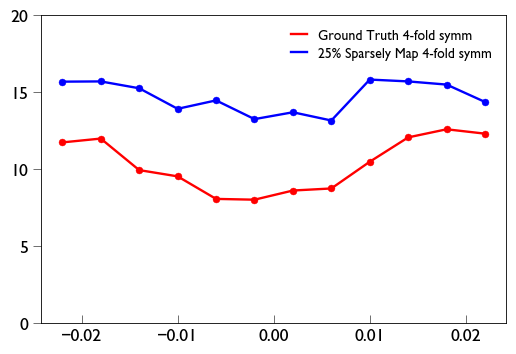

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_symm_snr_bp, 'r', label='Ground Truth 4-fold symm')
plot(d.en, liy_symm_snr_bp, 'ro',)

plot(d.en, rec_symm_snr_bp, 'b', label='25% Sparsely Map 4-fold symm')
plot(d.en, rec_symm_snr_bp, 'bo',)

# plot(d.en, liy_snr, 'r', label='Ground Truth')
# plot(d.en, liy_snr, 'ro',)

# plot(d.en, rec_snr, 'b', label='25% Sparsely Map')
# plot(d.en, rec_snr, 'bo',)

ylim(0, 20)
yticks([0, 5, 10, 15, 20])
legend()

savefig('../figures/snr linecut scheme 40 nm comparison bp symm.png', dpi=400, bbox_inches='tight', pad_inches=0)

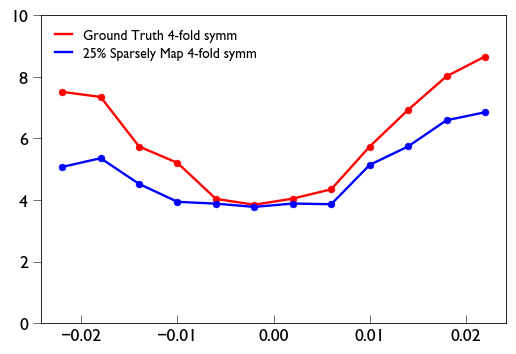

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_symm_snr, 'r', label='Ground Truth 4-fold symm')
plot(d.en, liy_symm_snr, 'ro',)

plot(d.en, rec_symm_snr, 'b', label='25% Sparsely Map 4-fold symm')
plot(d.en, rec_symm_snr, 'bo',)

# plot(d.en, liy_snr, 'r', label='Ground Truth')
# plot(d.en, liy_snr, 'ro',)

# plot(d.en, rec_snr, 'b', label='25% Sparsely Map')
# plot(d.en, rec_snr, 'bo',)

ylim(0, 10)
legend()

savefig('../figures/snr linecut scheme 40 nm comparison symm.png', dpi=400, bbox_inches='tight', pad_inches=0)

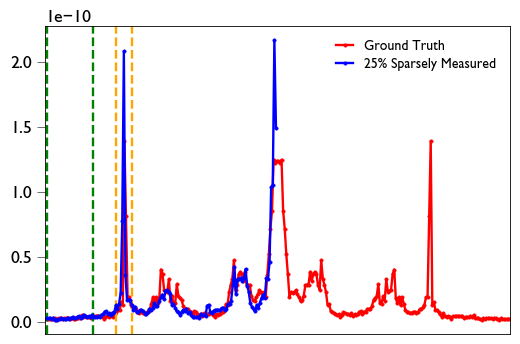

In [ ]:
x1 = linspace(-1.2, 1.2, num=len(r1))
x2 = linspace(-1.19, 1.19, num=len(r2))

figure(figsize=[6,4])
plot(x1, cut1[0], 'r.-', label='Ground Truth')
axvline(x1[30], linestyle='--', color='green')
axvline(-1.19, linestyle='--', color='green')

axvline(x1[45], linestyle='--', color='orange')
axvline(x1[55], linestyle='--', color='orange')
# figure(figsize=[6,4])
plot(x2[:len(x2)//2], cut2[0][:len(x2)//2] * sum(cut1[0])/sum(cut2[0]), 'b.-', label='25% Sparsely Measured')
# axvline(x2[30], linestyle='--', color='blue')
# axvline(x2[60], linestyle='--', color='orange')
# axvline(x2[90], linestyle='--', color='orange')
legend()

xlim(-1.2, 1.2)
xticks([])
savefig('../figures/snr linecut scheme 40 nm comparison 3.png', dpi=400, bbox_inches='tight', pad_inches=0)

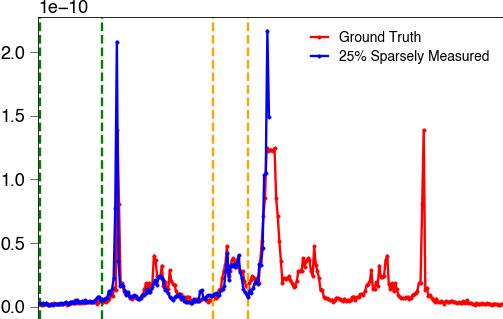

In [ ]:
x1 = linspace(-1.2, 1.2, num=len(r1))
x2 = linspace(-1.19, 1.19, num=len(r2))

figure(figsize=[6,4])
plot(x1, cut1[0], 'r.-', label='Ground Truth')
axvline(x1[40], linestyle='--', color='green')
axvline(-1.19, linestyle='--', color='green')

axvline(x1[110], linestyle='--', color='orange')
axvline(x1[132], linestyle='--', color='orange')
# figure(figsize=[6,4])
plot(x2[:len(x2)//2], cut2[0][:len(x2)//2] * sum(cut1[0])/sum(cut2[0]), 'b.-', label='25% Sparsely Measured')
# axvline(x2[30], linestyle='--', color='blue')
# axvline(x2[60], linestyle='--', color='orange')
# axvline(x2[90], linestyle='--', color='orange')
legend()

xlim(-1.2, 1.2)
xticks([])
savefig('../figures/snr linecut scheme 40 nm comparison scheme 2.png', dpi=400, bbox_inches='tight', pad_inches=0)

In [ ]:
liy_snr2 = []
for i in range(len(cut1)):
    noise = mean(cut1[i][:30])
    signal = mean(cut1[i][110:130])
    liy_snr2.append(signal / noise)

rec_snr2 = []
for i in range(len(cut2)):
    noise = mean(cut2[i][:30])
    signal = mean(cut2[i][110:130])
    rec_snr2.append(signal / noise)

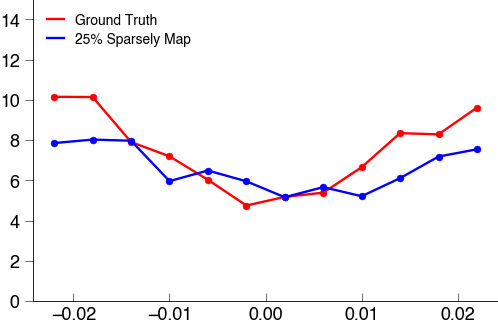

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_snr2, 'r', label='Ground Truth')
plot(d.en, liy_snr2, 'ro',)

plot(d.en, rec_snr2, 'b', label='25% Sparsely Map')
plot(d.en, rec_snr2, 'bo',)
ylim(0, 15)
legend(loc='upper left')

savefig('../figures/snr linecut scheme 40 nm comparison 2.png', dpi=400, bbox_inches='tight', pad_inches=0)

In [ ]:
liy_symm_snr2 = []
for i in range(len(cut1_symm)):
    noise = mean(cut1_symm[i][:30])
    signal = mean(cut1_symm[i][110:132])
    liy_symm_snr2.append(signal / noise)

rec_symm_snr2 = []
for i in range(len(cut2_symm)):
    noise = mean(cut2_symm[i][:30])
    signal = mean(cut2_symm[i][110:132])
    rec_symm_snr2.append(signal / noise)

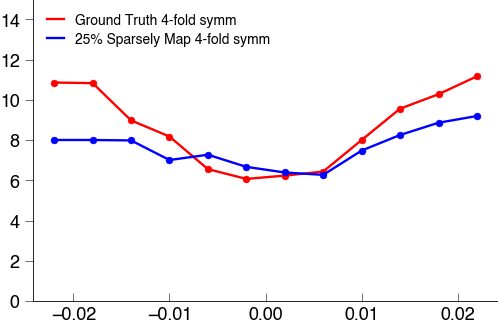

In [ ]:
figure(figsize=[6,4])
plot(d.en, liy_symm_snr2, 'r', label='Ground Truth 4-fold symm')
plot(d.en, liy_symm_snr2, 'ro',)

plot(d.en, rec_symm_snr2, 'b', label='25% Sparsely Map 4-fold symm')
plot(d.en, rec_symm_snr2, 'bo',)

ylim(0, 15)
legend(loc='upper left')

savefig('../figures/snr linecut scheme 40 nm comparison symm2.png', dpi=400, bbox_inches='tight', pad_inches=0)